# Validate metamodel vs dynamic SnapWave

Compare spectral metamodel (`hs`, `tp`, `tm01`, `dm`) against the dynamic
reference run (`SnapWave_CASES_Dynamic/Dynamic_Cases_198601.nc`).

Only **isobath** sites are compared. Default period metric is `tm01` (see
`validation.period_var` in `NorthCarolina.json`). Use `site_label="5m"` /
`"10m"` / `"15m"` for cluster validation.

Buoy validation (metamodel + dynamic + downscaled vs observations) lives in
`06_Validate_Against_Buoys.ipynb` via `val.validate_buoys()`.

In [1]:
from utils import metamodel as mm
from utils import validation as val

print(f"metamodel : {mm.spectral_output_path()}")
print(f"dynamic   : {val.dynamic_output_path()}")

metamodel : /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/outputs/spectral_metamodel.nc
dynamic   : /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/SnapWave_CASES_Dynamic/Dynamic_Cases_198601.nc


In [2]:
# Align on shared isobath sites and overlapping time steps.
time = "1986-01-15"

result = val.validate_against_dynamic(time=time)
meta, dynamic = result.metamodel, result.dynamic

print(f"{len(result.sites)} sites, {meta.sizes['time']} timesteps")

2026-06-17 15:51:37,125 - NorthCarolina.validation - INFO - Loading metamodel from /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/outputs/spectral_metamodel.nc
2026-06-17 15:51:37,287 - NorthCarolina.validation - INFO - Loading dynamic reference from /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/SnapWave_CASES_Dynamic/Dynamic_Cases_198601.nc
2026-06-17 15:51:37,306 - NorthCarolina.validation - INFO - Aligned 182 site(s), 24 time step(s) [1986-01-15 … 1986-01-15]
2026-06-17 15:51:37,340 - NorthCarolina.validation - INFO - Computed metrics (pooled grouping): 3 row(s)
2026-06-17 15:51:37,341 - NorthCarolina.validation - INFO - Hs: n=4368  RMSE=0.341  BIAS=0.118  R²=0.404
2026-06-17 15:51:37,341 - NorthCarolina.validation - INFO - Tp: n=4368  RMSE=0.780  BIAS=-0.174  R²=0.138
2026-06-17 15:51:37,342 - NorthCarolina.validation - INFO - Dm: n=4368  RMSE=57.610  BIAS=2.722  R²=0.377


182 sites, 24 timesteps


In [3]:
# Optional: validate a single isobath cluster
cluster = "15m"
cluster_result = val.validate_against_dynamic(time=time, site_label=cluster)
print(f"{cluster}: {len(cluster_result.sites)} sites")
cluster_result.metrics

2026-06-17 15:51:37,347 - NorthCarolina.validation - INFO - Loading metamodel from /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/outputs/spectral_metamodel.nc
2026-06-17 15:51:37,355 - NorthCarolina.validation - INFO - Loading dynamic reference from /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/SnapWave_CASES_Dynamic/Dynamic_Cases_198601.nc
2026-06-17 15:51:37,376 - NorthCarolina.validation - INFO - Aligned 78 site(s), 24 time step(s) [1986-01-15 … 1986-01-15]
2026-06-17 15:51:37,385 - NorthCarolina.validation - INFO - Computed metrics (pooled grouping): 3 row(s)
2026-06-17 15:51:37,386 - NorthCarolina.validation - INFO - Hs: n=1872  RMSE=0.192  BIAS=0.095  R²=0.699
2026-06-17 15:51:37,387 - NorthCarolina.validation - INFO - Tp: n=1872  RMSE=0.743  BIAS=-0.124  R²=0.158
2026-06-17 15:51:37,387 - NorthCarolina.validation - INFO - Dm: n=1872  RMSE=60.879  BIAS=5.176  R²=0.372


15m: 78 sites


,group,variable,label,n,bias,rmse,si,r2
0,all,hs,Hs,1872,0.094587,0.191674,0.131714,0.699076
1,all,tp,Tp,1872,-0.123725,0.743090,0.116660,0.157538
2,all,dm,Dm,1872,5.176431,60.879487,NaN,0.371727


In [4]:
# Pooled metrics (all sites × time)
result.metrics

,group,variable,label,n,bias,rmse,si,r2
0,all,hs,Hs,4368,0.118423,0.340530,0.234945,0.403580
1,all,tp,Tp,4368,-0.174002,0.780400,0.122013,0.137687
2,all,dm,Dm,4368,2.722400,57.609982,NaN,0.376667


In [5]:
# Metrics broken down by isobath depth (5 m / 10 m / 15 m)
val.metrics_table(meta, dynamic, groupby="site_label")

2026-06-17 15:51:37,459 - NorthCarolina.validation - INFO - Computed metrics (site_label grouping): 9 row(s)


,group,variable,label,n,bias,rmse,si,r2
0,10m,hs,Hs,1344,0.118148,0.216950,0.140146,0.658969
1,10m,tp,Tp,1344,-0.225489,0.811009,0.125885,0.135724
2,10m,dm,Dm,1344,1.804773,55.946445,NaN,0.409019
3,15m,hs,Hs,1872,0.094587,0.191674,0.131714,0.699076
4,15m,tp,Tp,1872,-0.123725,0.743090,0.116660,0.157538
5,15m,dm,Dm,1872,5.176431,60.879487,NaN,0.371727
6,5m,hs,Hs,1152,0.157478,0.570152,0.351363,0.050672
7,5m,tp,Tp,1152,-0.195633,0.802844,0.125295,0.101423
8,5m,dm,Dm,1152,-0.194837,53.942300,NaN,0.345778


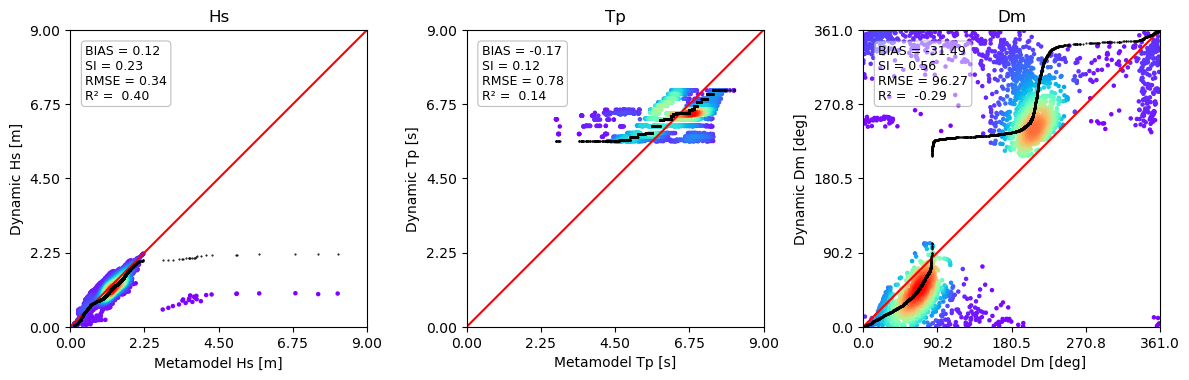

In [6]:
val.plot_scatter(meta, dynamic);

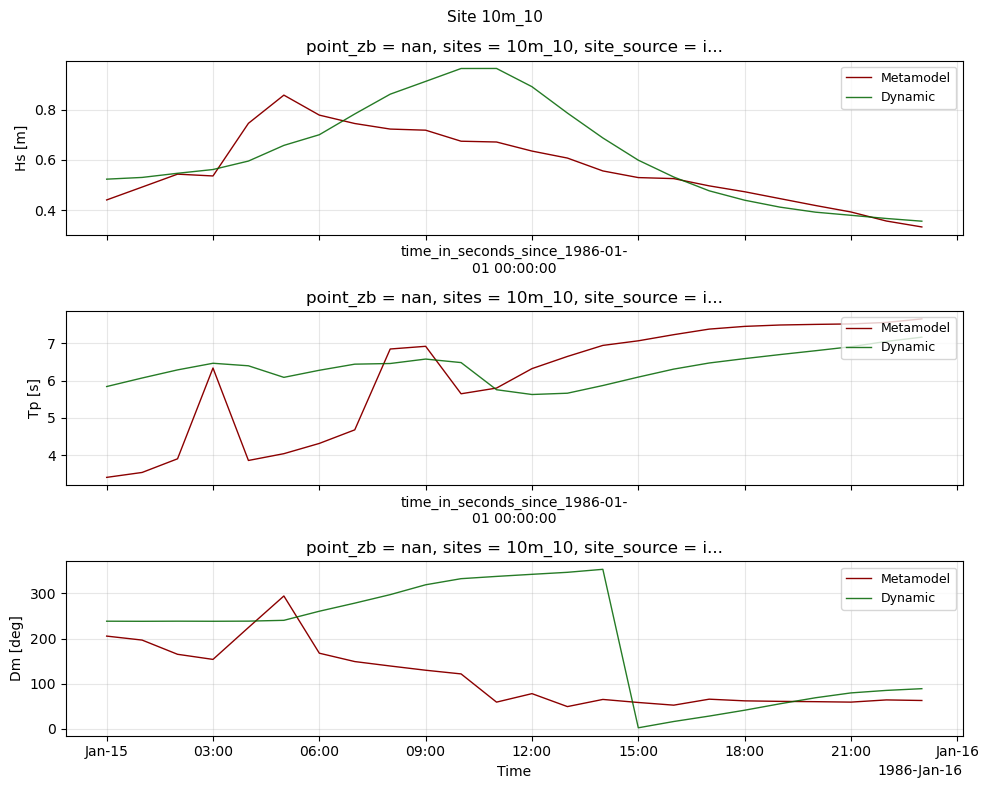

In [7]:
# Example time series at one isobath site
site = result.sites[0]
val.plot_timeseries(meta, dynamic, site);

2026-06-17 15:51:39,017 - NorthCarolina.validation - INFO - Computed metrics (site_label grouping): 9 row(s)
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using 

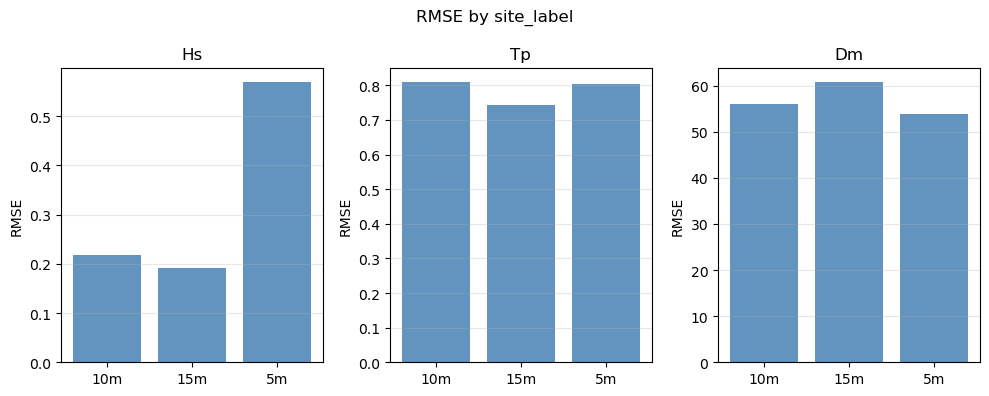

In [8]:
val.plot_metrics_by_label(meta, dynamic, metric="rmse");